# Rice leaf disease classification · MobileNetV3Large
### Train in Modal, inspect the results, download your model

**Input:** your data.zip containing the six class folders, optionally inside a parent folder.
**Output:** a ZIP with the best Keras model, verified mobile exports, ordered class labels,
reference prediction script, and evaluation reports.

This is a reproducible starting pipeline, not a guarantee of a particular accuracy.
The dataset has not been inspected or trained by the notebook author.
The six outputs assume one principal condition per photograph. Sheath blight photos should
include the relevant sheath tissue. Mixed diseases and unsupported conditions need separate validation.

## Before running
1. Import this .ipynb at [Modal Notebooks](https://modal.com/notebooks).
2. Select one **L4 GPU**, about **4 CPU cores and 16 GiB RAM** in kernel settings.
3. Attach a **Modal Volume** in the Files panel. Note its actual path under /mnt.
4. Upload data.zip to that Volume. Set the three paths in the configuration cell below.
5. Run installation in a fresh dedicated notebook; restart the kernel if requested.
   Continue from the configuration cell. Run the remaining cells in order, inspecting the data review.
6. Download the ZIP from the Files panel at the end; then stop the GPU kernel.

Use persistent storage for data and results. Files outside a Volume are temporary.
See [Modal notebook setup](https://modal.com/docs/guide/notebooks).
Training starts only when you execute the training cells. This notebook does not deploy a service.


## 1 · Install the pinned training environment
Run once per new container. Requires a Python 3.10–3.13 Linux kernel.
This dedicated TensorFlow setup removes JAX/JAXlib from the notebook environment to avoid
competing XLA libraries; it also installs TensorFlow's CUDA dependencies. Use a separate notebook
for other frameworks. Restart if the cell requests it, then continue at step 2.

TensorFlow 2.20.0 and Keras 3.11.3 are pinned for reproducibility; they are not claimed to be
the newest releases. [TensorFlow installation](https://www.tensorflow.org/install/pip).


In [1]:
import sys, subprocess, shutil, importlib.metadata as package_metadata

if not ((3, 10) <= sys.version_info[:2] <= (3, 13)):
    raise RuntimeError("Use a Python 3.10–3.13 kernel for the pinned TensorFlow environment.")
if not sys.platform.startswith("linux"):
    raise RuntimeError("This installation cell targets Modal's Linux notebook kernel.")
requirements = [
    "tensorflow[and-cuda]==2.20.0", "keras==3.11.3",
    "numpy==2.2.6", "pandas==2.2.3", "Pillow==11.3.0",
    "scikit-learn==1.7.2", "matplotlib==3.10.6", "scipy==1.15.3",
]
def installed_version(package):
    try:
        return package_metadata.version(package)
    except package_metadata.PackageNotFoundError:
        return None

module_names = {"scikit-learn": "sklearn", "Pillow": "PIL"}
loaded_before_install = "jax" in sys.modules or "jaxlib" in sys.modules
for requirement in requirements:
    package, version = requirement.split("==")
    package = package.split("[")[0]
    module = module_names.get(package, package)
    if module in sys.modules and installed_version(package) != version:
        loaded_before_install = True
uv = shutil.which("uv")
# uv's --python option belongs to the install/uninstall subcommand.
def package_command(action, packages):
    if uv:
        return [uv, "pip", action, "--python", sys.executable, *packages]
    return [sys.executable, "-m", "pip", action, *(["-y"] if action == "uninstall" else []), *packages]

installed = {d.metadata["Name"].lower() for d in package_metadata.distributions() if d.metadata["Name"]}
jax_packages = [p for p in ("jax", "jaxlib") if p in installed]
if jax_packages:
    subprocess.check_call(package_command("uninstall", jax_packages))
subprocess.check_call(package_command("install", requirements))
print("Installation complete.")
if loaded_before_install:
    raise RuntimeError("Restart the kernel now to load the installed libraries, then continue at step 2.")
print("Continue at step 2. Reinstall only after a new container starts.")


Using Python 3.12.6 environment at: /usr/local
Uninstalled 2 packages in 164ms
 - jax==0.7.1
 - jaxlib==0.7.1
Using Python 3.12.6 environment at: /usr/local
Resolved 64 packages in 581ms
Prepared 12 packages in 19.77s
Uninstalled 5 packages in 966ms


Installation complete.
Continue at step 2. Reinstall only after a new container starts.


Installed 12 packages in 926ms
 + astunparse==1.6.3
 + flatbuffers==25.12.19
 + gast==0.7.0
 + google-pasta==0.2.0
 + libclang==18.1.1
 - numpy==2.1.2
 + numpy==2.2.6
 - pandas==2.3.2
 + pandas==2.2.3
 - pillow==11.0.0
 + pillow==11.3.0
 - scikit-learn==1.7.1
 + scikit-learn==1.7.2
 - scipy==1.16.1
 + scipy==1.15.3
 + tensorflow==2.20.0
 + termcolor==3.3.0


## 2 · Set your paths
Replace VOLUME_ROOT with the **actual attached Volume path**, then set ZIP_PATH if needed.
RUN_NAME identifies an experiment. Reusing the same name resumes completed stages and interrupted
epoch backups. Use a new name when changing training settings. Early-stopping and learning-rate
patience counters restart after an interruption.

Optional GROUP_METADATA_CSV: a CSV with relative_path and group_id, identifying the same
plant/capture session (or farm for a stronger holdout). A template is generated after the audit.
Without this metadata, near-duplicate grouping reduces leakage but cannot prove farm independence.


In [3]:
from pathlib import Path
from collections import Counter
import zipfile

path = Path("/root/data.zip")

if not path.is_file():
    print(f"❌ File not found: {path}")

elif not zipfile.is_zipfile(path):
    print("❌ The file exists, but it is not a valid ZIP archive.")

else:
    print(f"✅ File found: {path}")
    print(f"Size: {path.stat().st_size / (1024**2):.2f} MB")

    try:
        with zipfile.ZipFile(path) as archive:
            print("Checking archive integrity—this may take a few minutes...")
            damaged_file = archive.testzip()

            if damaged_file:
                print(f"❌ Damaged file inside ZIP: {damaged_file}")
            else:
                print("✅ All stored files passed the ZIP integrity check.")

            extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}
            images = [
                name for name in archive.namelist()
                if not name.endswith("/")
                and "__MACOSX" not in name
                and not Path(name).name.startswith(".")
                and Path(name).suffix.lower() in extensions
            ]

            print(f"\nImage files found: {len(images)}")
            print("\nImages by folder:")
            for folder, count in sorted(
                Counter(str(Path(name).parent) for name in images).items()
            ):
                print(f"  {folder}: {count}")

    except Exception as error:
        print(f"❌ Could not finish checking: {error}")

✅ File found: /root/data.zip
Size: 1058.58 MB
Checking archive integrity—this may take a few minutes...
✅ All stored files passed the ZIP integrity check.

Image files found: 4843

Images by folder:
  Bacterial Leaf Blight: 675
  Brown Spot: 1628
  Healthy Rice Leaf: 646
  Leaf Blast: 634
  Leaf scald: 628
  Sheath Blight: 632


In [4]:
from pathlib import Path
import os
os.environ["KERAS_BACKEND"] = "tensorflow"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

# EDIT THESE PATHS to match the Modal Files panel.
VOLUME_ROOT = Path("/root")
ZIP_PATH = Path("/root/data.zip")
PROJECT_DIR = VOLUME_ROOT / "rice_project"
RUN_NAME = "mobilenetv3_run_01"
GROUP_METADATA_CSV = None  # Example: VOLUME_ROOT / "capture_groups.csv"

SEED = 42
BATCH_SIZE = 32
HEAD_EPOCHS = 10
FINE_TUNE_EPOCHS = 30
HEAD_LEARNING_RATE = 1e-3
FINE_TUNE_LEARNING_RATE = 1e-5
FINE_TUNE_BLOCKS = 3
DROPOUT = 0.30
L2_REGULARIZATION = 1e-4
EXPORT_INT8 = True
REQUIRE_GPU = True
# Thresholds chosen before seeing the test set; exports are compared on validation only.
MAX_QUANTIZED_F1_DROP = 0.005
MAX_QUANTIZED_AGREEMENT_DROP = 0.01

if not VOLUME_ROOT.is_dir():
    raise FileNotFoundError("Attach a Volume, then replace VOLUME_ROOT with its actual path.")

if not ZIP_PATH.is_file():
    raise FileNotFoundError(f"Upload data.zip or correct ZIP_PATH: {ZIP_PATH}")
if not PROJECT_DIR.resolve().is_relative_to(VOLUME_ROOT.resolve()):
    raise ValueError("PROJECT_DIR must stay inside the selected Volume.")
if Path(RUN_NAME).name != RUN_NAME or RUN_NAME in ("", ".", ".."):
    raise ValueError("RUN_NAME must be a simple folder name.")
RUN_DIR = PROJECT_DIR / "runs" / RUN_NAME
REPORT_DIR = RUN_DIR / "reports"
EXPORT_DIR = RUN_DIR / "export"
for directory in (RUN_DIR, REPORT_DIR, EXPORT_DIR):
    directory.mkdir(parents=True, exist_ok=True)
print("Results saved at:", RUN_DIR)
print("TEMPORARY STORAGE: download your model before stopping the kernel.")


Results saved at: /root/rice_project/runs/mobilenetv3_run_01
TEMPORARY STORAGE: download your model before stopping the kernel.


In [5]:
import os
import sys
import shutil
import subprocess

print("CUDA_VISIBLE_DEVICES:", repr(os.environ.get("CUDA_VISIBLE_DEVICES")))

print("\n--- NVIDIA GPU check ---")
command = shutil.which("nvidia-smi")
if command:
    result = subprocess.run(
        [command], capture_output=True, text=True, timeout=30
    )
    print(result.stdout)
    print(result.stderr)
else:
    print("nvidia-smi not found: GPU access is not confirmed.")

print("\n--- TensorFlow check in a fresh Python process ---")
check = """
import tensorflow as tf
print("TensorFlow version:", tf.__version__)
print("Built with CUDA:", tf.test.is_built_with_cuda())
print("Detected GPUs:", tf.config.list_physical_devices("GPU"))
"""
result = subprocess.run(
    [sys.executable, "-c", check],
    capture_output=True,
    text=True,
    timeout=60,
)
print(result.stdout)
print(result.stderr)

CUDA_VISIBLE_DEVICES: None

--- NVIDIA GPU check ---
Mon Oct 12 07:07:37 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 610.57.04              KMD Version: 610.57.04     CUDA UMD Version: 13.3     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA L4                      On  |   00000000:80:03.0 Off |                    0 |
| N/A   50C    P8             16W /   72W |       5MiB /  23034MiB |      0%      Default |
|                                         |                        |                  N

## 3 · Verify GPU and record the environment
The GPU check stops accidental long CPU training. Float32 training is deliberate: this model
fits comfortably on an L4 at batch size 32, and the exports stay straightforward.
If GPU memory is insufficient, start a new run with batch size 16.


In [6]:
import sys, json, random, platform, importlib.metadata, subprocess
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from IPython.display import display

tf.keras.utils.set_random_seed(SEED)
tf.keras.mixed_precision.set_global_policy("float32")
gpus = tf.config.list_physical_devices("GPU")
if REQUIRE_GPU and not gpus:
    raise RuntimeError(
        "TensorFlow cannot see a GPU. Select L4 in kernel settings, rerun installation "
        "in the new container, and restart the kernel. Do not continue on CPU by accident."
    )
for device in gpus:
    tf.config.experimental.set_memory_growth(device, True)
tf.config.experimental.enable_op_determinism()
print("TensorFlow:", tf.__version__, "| Keras:", tf.keras.__version__)
print("GPU devices:", gpus)
print("Class input: 224 × 224 RGB, float32 in [0,255]. Normalization is inside the model.")
freeze = subprocess.run(
    [sys.executable, "-m", "pip", "freeze"], text=True, capture_output=True)
if freeze.returncode == 0:
    (REPORT_DIR / "environment.txt").write_text(freeze.stdout)
else:
    (REPORT_DIR / "environment.txt").write_text("\n".join(
        f"{d.metadata['Name']}=={d.version}" for d in importlib.metadata.distributions()
        if d.metadata["Name"]))


TensorFlow: 2.20.0 | Keras: 3.11.3
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Class input: 224 × 224 RGB, float32 in [0,255]. Normalization is inside the model.


## 4 · Load dataset utilities
These utilities preserve the originals, reject unsafe ZIP paths, decode each image, correct
EXIF rotation, remove exact duplicate pixels, and cache RGB images at 224 × 224 with black
padding to preserve aspect ratio. Folder matching ignores case, spaces, underscores and hyphens.
Supported formats: JPEG, PNG, BMP, WebP and single-frame TIFF.


In [7]:
import hashlib
import json
import os
import re
import shutil
import stat
import zipfile
from pathlib import Path, PurePosixPath

import numpy as np
import pandas as pd
from PIL import Image, ImageOps

CLASS_NAMES = [
    "Bacterial Leaf Blight", "Brown Spot", "Healthy Rice Leaf",
    "Leaf Blast", "Leaf scald", "Sheath Blight",
]
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}
CLASS_LOOKUP = {re.sub(r"[^a-z0-9]", "", n.lower()): n for n in CLASS_NAMES}


def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def write_json(path, value):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(json.dumps(value, indent=2, allow_nan=False), encoding="utf-8")
    temporary.replace(path)


def extract_checked(archive, destination, max_bytes=30 * 1024**3):
    """No extraction outside destination; no symlinks or duplicate member names."""
    destination = Path(destination).resolve()
    marker = destination / ".extracted.json"
    archive_hash = sha256_file(archive)
    if marker.exists():
        if json.loads(marker.read_text())["sha256"] == archive_hash:
            return destination, archive_hash
        raise ValueError("Archive changed. Use a new PROJECT_DIR to preserve previous runs.")
    if destination.exists() and any(destination.iterdir()):
        raise ValueError("Incomplete extraction found. Choose a new PROJECT_DIR.")
    with zipfile.ZipFile(archive) as z:
        members = z.infolist()
        if len(members) > 100_000 or sum(m.file_size for m in members) > max_bytes:
            raise ValueError("Archive exceeds the configured extraction limit.")
        seen = set()
        for member in members:
            name = member.filename.replace("\\", "/")
            relative = PurePosixPath(name)
            mode = member.external_attr >> 16
            if (relative.is_absolute() or ".." in relative.parts or
                    not relative.parts or ":" in relative.parts[0] or
                    stat.S_ISLNK(mode)):
                raise ValueError(f"Unsafe ZIP entry: {member.filename}")
            target = (destination / str(relative)).resolve()
            if not target.is_relative_to(destination):
                raise ValueError(f"Unsafe ZIP entry: {member.filename}")
            if str(relative) in seen:
                raise ValueError(f"Repeated ZIP path: {member.filename}")
            seen.add(str(relative))
        destination.mkdir(parents=True, exist_ok=True)
        for member in members:
            target = destination / member.filename.replace("\\", "/")
            if member.is_dir():
                target.mkdir(parents=True, exist_ok=True)
            else:
                target.parent.mkdir(parents=True, exist_ok=True)
                with z.open(member) as source, open(target, "wb") as sink:
                    shutil.copyfileobj(source, sink)
    write_json(marker, {"sha256": archive_hash})
    return destination, archive_hash


def open_rgb(path):
    with Image.open(path) as source:
        if getattr(source, "n_frames", 1) != 1:
            raise ValueError("Multi-frame image: select one frame manually.")
        image = ImageOps.exif_transpose(source)
        if image.mode in ("RGBA", "LA") or "transparency" in image.info:
            rgba = image.convert("RGBA")
            background = Image.new("RGBA", rgba.size, (0, 0, 0, 255))
            image = Image.alpha_composite(background, rgba)
        return image.convert("RGB").copy()


def letterbox(image, size=224):
    scaled = ImageOps.contain(image, (size, size), Image.Resampling.BILINEAR)
    output = Image.new("RGB", (size, size), (0, 0, 0))
    output.paste(scaled, ((size - scaled.width) // 2, (size - scaled.height) // 2))
    return output


def dhash(image):
    gray = np.asarray(image.convert("L").resize((9, 8), Image.Resampling.BILINEAR))
    bits = (gray[:, 1:] > gray[:, :-1]).ravel()
    return int.from_bytes(np.packbits(bits).tobytes(), "big")


def build_inventory(raw_dir, cache_dir, report_dir):
    """Decode every image, quarantine broken/unknown entries, and remove exact repeats."""
    raw_dir, cache_dir, report_dir = map(Path, (raw_dir, cache_dir, report_dir))
    cache_dir.mkdir(parents=True, exist_ok=True)
    rows, rejected, duplicates, conflicts = [], [], [], []
    fingerprints = {}
    thumbnails = {}
    for path in sorted(raw_dir.rglob("*")):
        if not path.is_file() or "__MACOSX" in path.parts or path.name.startswith("."):
            continue
        relative = path.relative_to(raw_dir).as_posix()
        if path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue
        matched = {
            CLASS_LOOKUP[normalized]
            for part in path.relative_to(raw_dir).parts[:-1]
            if (normalized := re.sub(r"[^a-z0-9]", "", part.lower())) in CLASS_LOOKUP
        }
        if len(matched) != 1:
            rejected.append({"relative_path": relative, "reason": "Unknown or ambiguous class folder"})
            continue
        label = matched.pop()
        try:
            rgb = open_rgb(path)
            digest = hashlib.sha256(
                f"{rgb.width},{rgb.height}:".encode() + rgb.tobytes()
            ).hexdigest()
            if digest in fingerprints:
                first = fingerprints[digest]
                duplicate = {
                    "relative_path": relative, "kept_path": first["relative_path"],
                    "label": label, "kept_label": first["label"],
                }
                if first["label"] != label:
                    conflicts.append(duplicate)
                else:
                    duplicates.append(duplicate)
                continue
            cached = cache_dir / f"{digest}.png"
            letterbox(rgb).save(cached)
            row = {
                "relative_path": relative, "image_path": str(cached),
                "label": label, "label_id": CLASS_NAMES.index(label),
                "width": rgb.width, "height": rgb.height,
                "pixel_sha256": digest, "dhash": str(dhash(rgb)),
                "small_image": min(rgb.size) < 128,
            }
            fingerprints[digest] = row
            rows.append(row)
            thumbnails[digest] = np.asarray(
                rgb.resize((16, 16), Image.Resampling.BILINEAR), dtype=np.int16
            )
        except (OSError, ValueError, Image.DecompressionBombError) as exc:
            rejected.append({"relative_path": relative, "reason": str(exc)})
    pd.DataFrame(rejected, columns=["relative_path", "reason"]).to_csv(
        report_dir / "rejected_images.csv", index=False)
    for name, entries in [("exact_duplicates", duplicates), ("label_conflicts", conflicts)]:
        pd.DataFrame(entries, columns=[
            "relative_path", "kept_path", "label", "kept_label"
        ]).to_csv(report_dir / f"{name}.csv", index=False)
    frame = pd.DataFrame(rows)
    frame.to_csv(report_dir / "inventory.csv", index=False)
    if conflicts:
        raise ValueError("Identical images have different labels. Resolve label_conflicts.csv first.")
    if frame.empty:
        raise ValueError("No readable images found inside the six recognized class folders.")
    missing = set(CLASS_NAMES) - set(frame.label)
    if missing:
        raise ValueError(f"Missing classes: {sorted(missing)}. Check folder spelling.")
    return frame.reset_index(drop=True), thumbnails


class UnionFind:
    def __init__(self, count):
        self.parent = list(range(count))

    def find(self, index):
        while self.parent[index] != index:
            self.parent[index] = self.parent[self.parent[index]]
            index = self.parent[index]
        return index

    def union(self, left, right):
        left, right = self.find(left), self.find(right)
        if left != right:
            self.parent[right] = left


class BKTree:
    """Hamming-distance search over 64-bit perceptual hashes."""
    def __init__(self):
        self.root = None

    def insert(self, value, index):
        if self.root is None:
            self.root = [value, [index], {}]
            return
        node = self.root
        while True:
            distance = (value ^ node[0]).bit_count()
            if distance == 0:
                node[1].append(index)
                return
            if distance not in node[2]:
                node[2][distance] = [value, [index], {}]
                return
            node = node[2][distance]

    def search(self, value, radius):
        stack = [self.root] if self.root is not None else []
        while stack:
            node = stack.pop()
            distance = (value ^ node[0]).bit_count()
            if distance <= radius:
                yield from node[1]
            stack.extend(child for edge, child in node[2].items()
                         if distance - radius <= edge <= distance + radius)


def add_groups(frame, thumbnails, metadata_csv=None):
    frame = frame.copy().reset_index(drop=True)
    union, tree = UnionFind(len(frame)), BKTree()
    near_pairs = []
    for index, row in enumerate(frame.itertuples()):
        value = int(row.dhash)
        for other in tree.search(value, 3):
            previous = frame.iloc[other]
            aspect_difference = abs(np.log(
                (row.width / row.height) / (previous.width / previous.height)))
            difference = float(np.abs(
                thumbnails[row.pixel_sha256] - thumbnails[previous.pixel_sha256]
            ).mean())
            if aspect_difference < 0.05 and difference <= 12:
                union.union(index, other)
                near_pairs.append({
                    "left": row.relative_path, "right": previous.relative_path,
                    "left_label": row.label, "right_label": previous.label,
                    "thumbnail_difference": difference,
                })
        tree.insert(value, index)
    if metadata_csv:
        metadata = pd.read_csv(metadata_csv, dtype=str).fillna("")
        if not {"relative_path", "group_id"} <= set(metadata.columns):
            raise ValueError("Group metadata needs relative_path and group_id columns.")
        if metadata.relative_path.duplicated().any():
            raise ValueError("Group metadata has repeated relative_path values.")
        mapping = dict(zip(metadata.relative_path, metadata.group_id))
        unmatched = set(mapping) - set(frame.relative_path)
        if unmatched:
            print(f"Metadata paths absent after cleaning: {len(unmatched)}")
        first_member = {}
        for index, path in enumerate(frame.relative_path):
            group = mapping.get(path, "").strip()
            if group:
                if group in first_member:
                    union.union(index, first_member[group])
                else:
                    first_member[group] = index
        frame["capture_group_known"] = [
            bool(mapping.get(path, "").strip()) for path in frame.relative_path
        ]
    else:
        frame["capture_group_known"] = False
    frame["group_id"] = [f"group_{union.find(i):06d}" for i in range(len(frame))]
    return frame, pd.DataFrame(near_pairs, columns=[
        "left", "right", "left_label", "right_label", "thumbnail_difference"
    ])


def grouped_split(frame, seed=42, trials=600):
    """Search reproducible group assignments using labels only, never model results."""
    frame = frame.copy()
    table = pd.crosstab(frame.group_id, frame.label_id).reindex(
        columns=range(len(CLASS_NAMES)), fill_value=0)
    counts = table.to_numpy()
    if ((counts > 0).sum(axis=0) < 10).any():
        raise ValueError("Fewer than 10 independent groups in a class. Collect more groups.")
    proportions = np.array([0.70, 0.15, 0.15])
    desired = proportions[:, None] * counts.sum(axis=0)[None, :]
    rng, best = np.random.default_rng(seed), None
    best_error = float("inf")
    for _ in range(trials):
        assignment = rng.choice(3, len(counts), p=proportions)
        actual = np.zeros_like(desired)
        np.add.at(actual, assignment, counts)
        if actual.min() < 3:
            continue
        error = float(np.square((actual - desired) / np.maximum(desired, 1)).mean())
        if error < best_error:
            best, best_error = assignment, error
    if best is None:
        raise ValueError("Unable to create three usable grouped splits. Inspect group sizes.")
    mapping = dict(zip(table.index, np.array(["train", "validation", "test"])[best]))
    frame["split"] = frame.group_id.map(mapping)
    if frame.groupby("group_id").split.nunique().max() != 1:
        raise AssertionError("Group leakage detected.")
    if frame.groupby("pixel_sha256").split.nunique().max() != 1:
        raise AssertionError("Duplicate leakage detected.")
    return frame


In [8]:
archive_sha256 = sha256_file(ZIP_PATH)
DATA_DIR = PROJECT_DIR / "datasets" / archive_sha256[:16]
RAW_DIR = DATA_DIR / "raw"
CACHE_DIR = DATA_DIR / "rgb224"
print("Checking and extracting the ZIP...")
_, verified_archive_hash = extract_checked(ZIP_PATH, RAW_DIR)
assert verified_archive_hash == archive_sha256
inventory, thumbnails = build_inventory(RAW_DIR, CACHE_DIR, REPORT_DIR)
display(inventory.groupby("label").agg(
    usable_images=("relative_path", "size"),
    small_images=("small_image", "sum")).reindex(CLASS_NAMES))
print("Usable images:", len(inventory))
print("Read rejected_images.csv and exact_duplicates.csv in", REPORT_DIR)
template = inventory[["relative_path"]].copy()
template["group_id"] = ""
template.to_csv(REPORT_DIR / "capture_groups_template.csv", index=False)
if inventory.groupby("label").size().min() < 800:
    print("Some classes have fewer than 800 usable unique images after cleaning. Counts are not guarantees.")


Checking and extracting the ZIP...


,usable_images,small_images
label,,
Bacterial Leaf Blight,675,0
Brown Spot,1612,6
Healthy Rice Leaf,643,0
Leaf Blast,619,0
Leaf scald,628,0
Sheath Blight,628,0


Usable images: 4805
Read rejected_images.csv and exact_duplicates.csv in /root/rice_project/runs/mobilenetv3_run_01/reports
Some classes have fewer than 800 usable unique images after cleaning. Counts are not guarantees.


## 5 · Inspect the data before spending GPU time on training
Check that each row below matches its label and that lesions remain visible at 224 × 224.
Review rejected_images.csv; unknown class folders must not be silently overlooked.
Identical pixels with contradictory labels stop the audit until corrected.

Near-duplicate detection below is conservative: dHash distance ≤ 3, similar aspect ratio,
and similar color thumbnails. It can miss rotations/crops and can group similar-looking images.
Review near_duplicates.csv, especially pairs with different labels. Original images are never deleted.
If one class consistently has a different background, collect more varied images before trusting results.


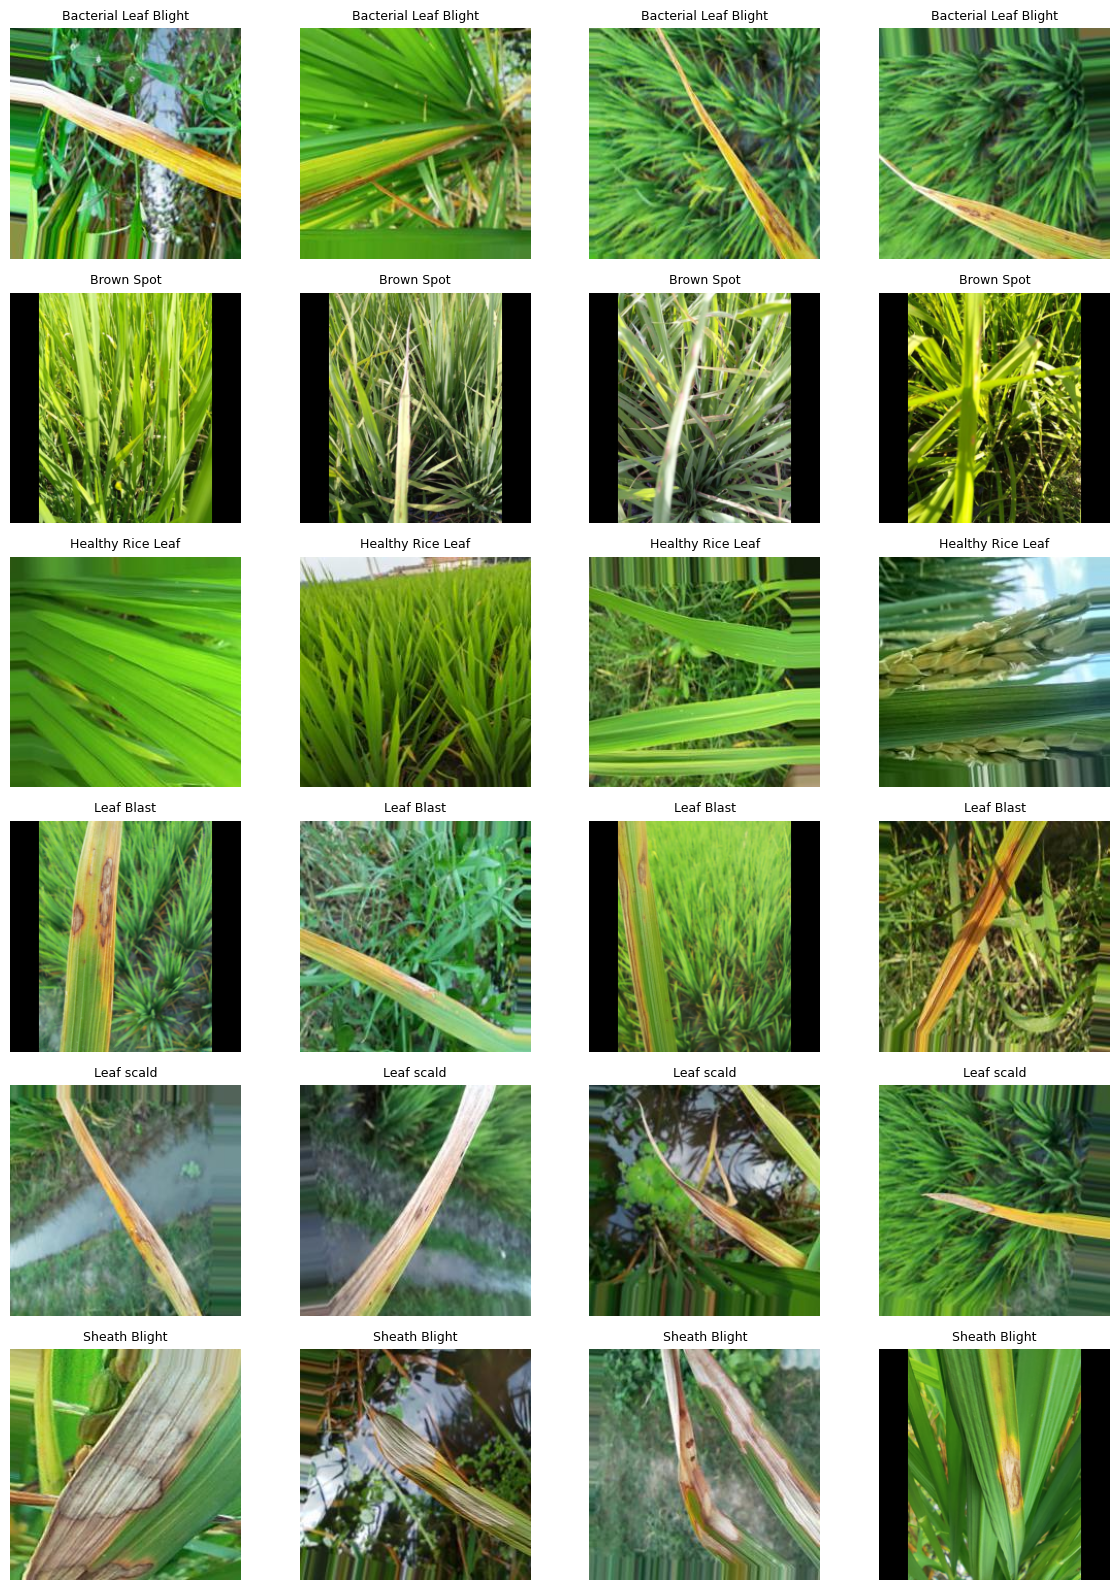

In [9]:
fig, axes = plt.subplots(6, 4, figsize=(12, 16))
for row_index, label in enumerate(CLASS_NAMES):
    candidates = inventory[inventory.label == label].sample(
        min(4, sum(inventory.label == label)), random_state=SEED)
    for axis in axes[row_index]:
        axis.axis("off")
    for column, row in enumerate(candidates.itertuples()):
        axes[row_index, column].imshow(Image.open(row.image_path))
        axes[row_index, column].set_title(label, fontsize=9)
fig.tight_layout()
fig.savefig(REPORT_DIR / "dataset_samples.png", dpi=120)
plt.show()


In [10]:
grouped, near_pairs = add_groups(inventory, thumbnails, GROUP_METADATA_CSV)
near_pairs.to_csv(REPORT_DIR / "near_duplicates.csv", index=False)
print("Near-duplicate pairs grouped:", len(near_pairs))
if len(near_pairs):
    display(near_pairs.head(12))
print("Largest group:", int(grouped.groupby("group_id").size().max()), "images")
if not grouped.capture_group_known.all():
    print("LIMITATION: some/all capture groups are unknown; field independence is unverified.")

experiment_config = {
    "archive_sha256": archive_sha256, "seed": SEED,
    "metadata_sha256": sha256_file(GROUP_METADATA_CSV) if GROUP_METADATA_CSV else None,
    "batch_size": BATCH_SIZE, "head_epochs": HEAD_EPOCHS,
    "fine_tune_epochs": FINE_TUNE_EPOCHS, "head_lr": HEAD_LEARNING_RATE,
    "fine_tune_lr": FINE_TUNE_LEARNING_RATE, "fine_tune_blocks": FINE_TUNE_BLOCKS,
    "dropout": DROPOUT, "l2": L2_REGULARIZATION,
    "class_names": CLASS_NAMES, "tensorflow": tf.__version__,
    "keras": tf.keras.__version__, "export_int8": EXPORT_INT8,
    "max_quantized_f1_drop": MAX_QUANTIZED_F1_DROP,
    "max_quantized_agreement_drop": MAX_QUANTIZED_AGREEMENT_DROP,
    "pipeline_version": "1.0",
}
config_path = RUN_DIR / "experiment_config.json"
manifest_path = REPORT_DIR / "split_manifest.csv"
if config_path.exists():
    if json.loads(config_path.read_text()) != experiment_config:
        raise ValueError("Settings changed. Set a NEW RUN_NAME to preserve this experiment.")
else:
    write_json(config_path, experiment_config)
if manifest_path.exists():
    manifest = pd.read_csv(manifest_path, dtype={"dhash": str})
    if set(manifest.pixel_sha256) != set(grouped.pixel_sha256):
        raise ValueError("Dataset changed. Start a new RUN_NAME.")
else:
    manifest = grouped_split(grouped, seed=SEED)
    manifest.to_csv(manifest_path, index=False)
assert manifest.groupby("group_id").split.nunique().max() == 1
assert manifest.groupby("pixel_sha256").split.nunique().max() == 1
train_frame = manifest[manifest.split == "train"].reset_index(drop=True)
validation_frame = manifest[manifest.split == "validation"].reset_index(drop=True)
test_frame = manifest[manifest.split == "test"].reset_index(drop=True)
display(pd.crosstab(manifest.label, manifest.split).reindex(CLASS_NAMES)[["train", "validation", "test"]])
print("Fixed splits saved. Test images are held back until final evaluation.")
if hasattr(os, "sync"):
    os.sync()


Near-duplicate pairs grouped: 247


,left,right,left_label,right_label,thumbnail_difference
0,Bacterial Leaf Blight/IMG_20231014_173627.jpg,Bacterial Leaf Blight/IMG_20231014_173626.jpg,Bacterial Leaf Blight,Bacterial Leaf Blight,3.583333
1,Bacterial Leaf Blight/IMG_20231018_143107.jpg,Bacterial Leaf Blight/IMG_20231018_143106.jpg,Bacterial Leaf Blight,Bacterial Leaf Blight,6.721354
2,Bacterial Leaf Blight/IMG_20231018_143623_1.jpg,Bacterial Leaf Blight/IMG_20231018_143623.jpg,Bacterial Leaf Blight,Bacterial Leaf Blight,3.812500
3,Brown Spot/100581.jpg,Brown Spot/100489.jpg,Brown Spot,Brown Spot,5.821615
4,Brown Spot/101341.jpg,Brown Spot/101017.jpg,Brown Spot,Brown Spot,7.147135
5,Brown Spot/101372.jpg,Brown Spot/100532.jpg,Brown Spot,Brown Spot,6.789062
6,Brown Spot/101411.jpg,Brown Spot/100067.jpg,Brown Spot,Brown Spot,5.501302
7,Brown Spot/102171.jpg,Brown Spot/100838.jpg,Brown Spot,Brown Spot,5.979167
8,Brown Spot/102212.jpg,Brown Spot/101338.jpg,Brown Spot,Brown Spot,11.061198
9,Brown Spot/102504.jpg,Brown Spot/102077.jpg,Brown Spot,Brown Spot,4.451823


Largest group: 11 images
LIMITATION: some/all capture groups are unknown; field independence is unverified.


split,train,validation,test
label,,,
Bacterial Leaf Blight,468,102,105
Brown Spot,1138,228,246
Healthy Rice Leaf,443,101,99
Leaf Blast,427,96,96
Leaf scald,438,94,96
Sheath Blight,441,95,92


Fixed splits saved. Test images are held back until final evaluation.


## 6 · Build the input pipeline
Only training images are augmented. Validation and test inputs are deterministic.
The sparse labels use the exact class order saved in class_names.json.
Moderate augmentation, dropout and a small L2 penalty help control overfitting;
they do not replace varied data. Class weighting is enabled only if class imbalance exceeds 1.5×.


In [11]:
augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal_and_vertical", seed=SEED),
    tf.keras.layers.RandomRotation(0.08, fill_mode="constant", fill_value=0, seed=SEED + 1),
    tf.keras.layers.RandomZoom(0.10, fill_mode="constant", fill_value=0, seed=SEED + 2),
    tf.keras.layers.RandomContrast(0.10, seed=SEED + 3),
    tf.keras.layers.RandomBrightness(0.10, value_range=(0, 255), seed=SEED + 4),
], name="training_augmentation")


I0000 00:00:1791789208.746217     157 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 20859 MB memory:  -> device: 0, name: NVIDIA L4, pci bus id: 0000:80:03.0, compute capability: 8.9


In [12]:
import time
import tensorflow as tf
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report,
    confusion_matrix, f1_score, precision_recall_fscore_support,
)


def decode_cached(path, label):
    image = tf.io.decode_png(tf.io.read_file(path), channels=3)
    image = tf.ensure_shape(image, (224, 224, 3))
    return tf.cast(image, tf.float32), label


def make_dataset(frame, training=False):
    dataset = tf.data.Dataset.from_tensor_slices((
        frame.image_path.astype(str).to_numpy(),
        frame.label_id.to_numpy(dtype=np.int32),
    ))
    if training:
        dataset = dataset.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
    dataset = dataset.map(decode_cached, num_parallel_calls=tf.data.AUTOTUNE)
    dataset = dataset.batch(BATCH_SIZE)
    if training:
        dataset = dataset.map(
            lambda x, y: (tf.clip_by_value(augmentation(x, training=True), 0, 255), y),
            num_parallel_calls=tf.data.AUTOTUNE,
        )
    options = tf.data.Options()
    options.experimental_deterministic = True
    return dataset.with_options(options).prefetch(tf.data.AUTOTUNE)


def compile_model(model, learning_rate):
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate, clipnorm=1.0),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(),
        metrics=[tf.keras.metrics.SparseCategoricalAccuracy(name="accuracy")],
        jit_compile=False,
    )


class SyncPersistentStorage(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        if hasattr(os, "sync"):
            os.sync()


def fit_stage(model, stage_name, epochs):
    stage_dir = RUN_DIR / stage_name
    stage_dir.mkdir(exist_ok=True)
    checkpoint = stage_dir / "best.keras"
    completed = stage_dir / "complete.json"
    log_path = stage_dir / "history.csv"
    if completed.exists() and checkpoint.exists():
        print(f"{stage_name}: already complete; using its saved best checkpoint.")
        return tf.keras.models.load_model(checkpoint, compile=False)
    initial_best = None
    if log_path.exists() and checkpoint.exists():
        previous = pd.read_csv(log_path)
        if "val_loss" in previous and len(previous):
            initial_best = float(previous.val_loss.min())
    callbacks = [
        tf.keras.callbacks.ModelCheckpoint(
            str(checkpoint), monitor="val_loss", mode="min",
            save_best_only=True, initial_value_threshold=initial_best, verbose=1,
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.5, patience=2,
            min_lr=1e-7, verbose=1,
        ),
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=6, min_delta=0.001,
            restore_best_weights=False, verbose=1,
        ),
        tf.keras.callbacks.TerminateOnNaN(),
        tf.keras.callbacks.CSVLogger(str(log_path), append=log_path.exists()),
        tf.keras.callbacks.BackupAndRestore(
            backup_dir=str(stage_dir / "resume"), save_freq="epoch",
            delete_checkpoint=False,
        ),
        SyncPersistentStorage(),
    ]
    model.fit(
        train_ds, validation_data=validation_ds, epochs=epochs,
        class_weight=class_weights, callbacks=callbacks, verbose=2,
    )
    if not checkpoint.exists():
        raise RuntimeError("Training did not produce a finite best checkpoint.")
    history = pd.read_csv(log_path)
    if not np.isfinite(history[["loss", "val_loss"]].to_numpy()).all():
        raise RuntimeError("Non-finite training loss. Inspect logs and retry with a lower learning rate in a new run.")
    write_json(completed, {"checkpoint": str(checkpoint)})
    if hasattr(os, "sync"):
        os.sync()
    return tf.keras.models.load_model(checkpoint, compile=False)


def predict_frame(model, frame):
    predictions = model.predict(make_dataset(frame), verbose=0)
    if not np.isfinite(predictions).all():
        raise ValueError("Non-finite predictions.")
    return predictions


def metrics_for(frame, probabilities):
    true = frame.label_id.to_numpy(dtype=int)
    predicted = probabilities.argmax(axis=1)
    probabilities = np.clip(probabilities, 1e-7, 1)
    return {
        "images": int(len(frame)),
        "accuracy": float(accuracy_score(true, predicted)),
        "balanced_accuracy": float(balanced_accuracy_score(true, predicted)),
        "macro_f1": float(f1_score(true, predicted, average="macro", zero_division=0)),
        "cross_entropy": float(-np.log(probabilities[np.arange(len(true)), true]).mean()),
    }


def save_predictions(frame, probabilities, path):
    output = frame[["relative_path", "label", "label_id", "group_id", "split"]].copy()
    output["predicted_class"] = np.array(CLASS_NAMES)[probabilities.argmax(axis=1)]
    output["score"] = probabilities.max(axis=1)
    for index, name in enumerate(CLASS_NAMES):
        output[f"score_{name}"] = probabilities[:, index]
    output.to_csv(path, index=False)


def tflite_predict(model_path, frame):
    interpreter = tf.lite.Interpreter(model_path=str(model_path), num_threads=2)
    interpreter.allocate_tensors()
    input_details = interpreter.get_input_details()[0]
    output_details = interpreter.get_output_details()[0]
    results = []
    for path in frame.image_path:
        values = np.asarray(Image.open(path).convert("RGB"), dtype=np.float32)[None]
        if np.issubdtype(input_details["dtype"], np.integer):
            scale, zero = input_details["quantization"]
            if scale <= 0:
                raise ValueError("Invalid input quantization scale.")
            bounds = np.iinfo(input_details["dtype"])
            values = np.clip(np.rint(values / scale + zero), bounds.min, bounds.max)
        interpreter.set_tensor(input_details["index"], values.astype(input_details["dtype"]))
        interpreter.invoke()
        result = interpreter.get_tensor(output_details["index"])[0]
        if np.issubdtype(output_details["dtype"], np.integer):
            scale, zero = output_details["quantization"]
            result = (result.astype(np.float32) - zero) * scale
        results.append(result)
    return np.asarray(results)


Class weights: {0: 1.1948005698005697, 1: 0.4913591095489162, 2: 1.262227238525207, 3: 1.3095238095238095, 4: 1.2766362252663623, 5: 1.2679516250944822}


2026-10-12 07:13:50.312512: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_19}}


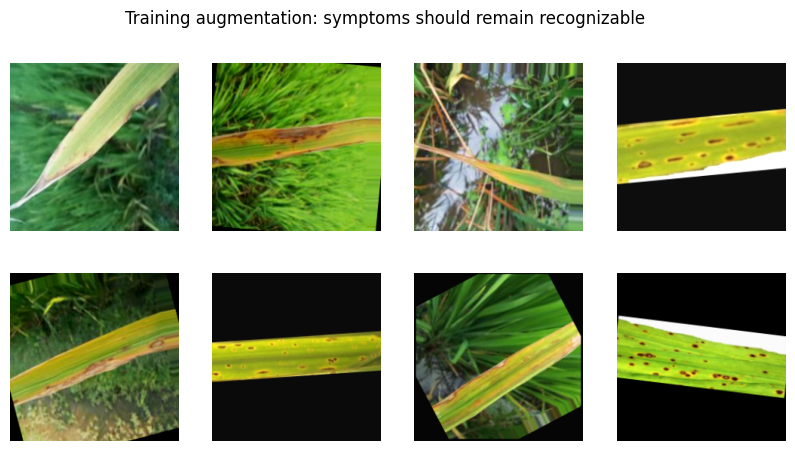

In [13]:
train_ds = make_dataset(train_frame, training=True)
validation_ds = make_dataset(validation_frame)
counts = train_frame.label_id.value_counts().sort_index()
class_weights = (
    {int(k): float(len(train_frame) / (6 * v)) for k, v in counts.items()}
    if counts.max() / counts.min() > 1.5 else None
)
print("Class weights:", class_weights or "not needed")
preview_images, _ = next(iter(train_ds))
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for index, axis in enumerate(axes.flat):
    axis.imshow(preview_images[index % len(preview_images)].numpy().astype("uint8"))
    axis.axis("off")
fig.suptitle("Training augmentation: symptoms should remain recognizable")
plt.show()


## 7 · Build MobileNetV3Large
ImageNet pretrained backbone, width 1.0, 224 × 224 → global average pooling → dropout →
six-class softmax. The usual 5.4M parameter figure includes a different original classifier;
the actual parameter count is printed below.

The model accepts raw RGB float32 values in [0,255]. Keras MobileNetV3 handles normalization
internally. Random augmentation is outside the model, so it is absent from mobile exports.
[Model documentation](https://keras.io/api/applications/mobilenet/mobilenet_models/).


In [14]:
tf.keras.utils.set_random_seed(SEED)
backbone = tf.keras.applications.MobileNetV3Large(
    input_shape=(224, 224, 3), alpha=1.0, minimalistic=False,
    include_top=False, weights="imagenet", include_preprocessing=True,
)
backbone.trainable = False
inputs = tf.keras.Input(shape=(224, 224, 3), dtype="float32", name="rgb_image")
# training=False keeps batch-normalization statistics fixed even during fine-tuning.
features = backbone(inputs, training=False)
features = tf.keras.layers.GlobalAveragePooling2D(name="global_average")(features)
features = tf.keras.layers.Dropout(DROPOUT, name="dropout")(features)
outputs = tf.keras.layers.Dense(
    6, activation="softmax", dtype="float32", name="disease_probabilities",
    kernel_regularizer=tf.keras.regularizers.l2(L2_REGULARIZATION),
)(features)
model = tf.keras.Model(inputs, outputs, name="rice_mobilenetv3large")
BACKBONE_NAME = backbone.name
compile_model(model, HEAD_LEARNING_RATE)
print("Total parameters:", f"{model.count_params():,}")
model.summary()
write_json(EXPORT_DIR / "class_names.json", CLASS_NAMES)
(EXPORT_DIR / "labels.txt").write_text("\n".join(CLASS_NAMES) + "\n")


12683000/12683000 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Total parameters: 3,002,118


Model: "rice_mobilenetv3large"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ rgb_image (InputLayer)               │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ MobileNetV3Large (Functional)        │ (None, 7, 7, 960)           │       2,996,352 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average                       │ (None, 960)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 960)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ disease_probabilities (Dense)        │ (None, 6)                   │           5,766 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,002,118 (11.45 MB)

 Trainable params: 5,766 (22.52 KB)

 Non-trainable params: 2,996,352 (11.43 MB)

87

## 8 · Stage A: learn the classifier
Up to 10 epochs at learning rate 0.001. Validation loss controls checkpointing, learning-rate
reduction and early stopping. Reports and resumable epoch backups are saved to the Volume.


In [15]:
model = fit_stage(model, "stage_a_head", HEAD_EPOCHS)


Epoch 1/10


2026-10-12 07:14:19.500389: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_19}}



Epoch 1: val_loss improved from None to 0.94212, saving model to /root/rice_project/runs/mobilenetv3_run_01/stage_a_head/best.keras
105/105 - 64s - 613ms/step - accuracy: 0.4402 - loss: 1.4596 - val_accuracy: 0.6466 - val_loss: 0.9421 - learning_rate: 1.0000e-03
Epoch 2/10

Epoch 2: val_loss improved from 0.94212 to 0.72025, saving model to /root/rice_project/runs/mobilenetv3_run_01/stage_a_head/best.keras
105/105 - 48s - 458ms/step - accuracy: 0.6459 - loss: 0.9922 - val_accuracy: 0.7416 - val_loss: 0.7202 - learning_rate: 1.0000e-03
Epoch 3/10

Epoch 3: val_loss improved from 0.72025 to 0.63202, saving model to /root/rice_project/runs/mobilenetv3_run_01/stage_a_head/best.keras
105/105 - 47s - 452ms/step - accuracy: 0.6999 - loss: 0.8674 - val_accuracy: 0.7640 - val_loss: 0.6320 - learning_rate: 1.0000e-03
Epoch 4/10

Epoch 4: val_loss did not improve from 0.63202
105/105 - 49s - 466ms/step - accuracy: 0.7198 - loss: 0.7876 - val_accuracy: 0.7751 - val_loss: 0.6409 - learning_rate: 1

## 9 · Stage B: fine-tune the last three blocks
Start from Stage A's best model. Train the final three inverted-residual blocks plus the final
convolution at learning rate 0.00001. Batch normalization remains frozen. If the notebook is
interrupted, rerun the setup/data cells and the training cells with the same RUN_NAME.
[Transfer-learning method](https://www.tensorflow.org/tutorials/images/transfer_learning).


In [16]:
backbone = next(layer for layer in model.layers if isinstance(layer, tf.keras.Model))
block_numbers = sorted({
    int(match.group(1)) for layer in backbone.layers
    if (match := re.search(r"expanded_conv_(\d+)(?:_|/)", layer.name))
})
if len(block_numbers) < FINE_TUNE_BLOCKS:
    raise RuntimeError("Unexpected backbone layer names. Check the pinned Keras version.")
first_selected = block_numbers[-FINE_TUNE_BLOCKS]
first_index = next(
    i for i, layer in enumerate(backbone.layers)
    if re.search(rf"expanded_conv_{first_selected}(?:_|/)", layer.name)
)
backbone.trainable = True
for index, layer in enumerate(backbone.layers):
    layer.trainable = (
        index >= first_index and not isinstance(layer, tf.keras.layers.BatchNormalization)
    )
compile_model(model, FINE_TUNE_LEARNING_RATE)
print("First fine-tuned block:", first_selected)
print("Trainable parameters:", sum(int(np.prod(w.shape)) for w in model.trainable_weights))
model = fit_stage(model, "stage_b_fine_tune", FINE_TUNE_EPOCHS)


First fine-tuned block: 12
Trainable parameters: 2171982
Epoch 1/30


2026-10-12 07:23:20.500678: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_19}}



Epoch 1: val_loss improved from None to 0.47735, saving model to /root/rice_project/runs/mobilenetv3_run_01/stage_b_fine_tune/best.keras
105/105 - 67s - 636ms/step - accuracy: 0.7937 - loss: 0.5962 - val_accuracy: 0.8142 - val_loss: 0.4773 - learning_rate: 1.0000e-05
Epoch 2/30

Epoch 2: val_loss improved from 0.47735 to 0.46495, saving model to /root/rice_project/runs/mobilenetv3_run_01/stage_b_fine_tune/best.keras
105/105 - 49s - 464ms/step - accuracy: 0.8113 - loss: 0.5505 - val_accuracy: 0.8268 - val_loss: 0.4649 - learning_rate: 1.0000e-05
Epoch 3/30

Epoch 3: val_loss improved from 0.46495 to 0.44677, saving model to /root/rice_project/runs/mobilenetv3_run_01/stage_b_fine_tune/best.keras
105/105 - 50s - 476ms/step - accuracy: 0.8209 - loss: 0.5316 - val_accuracy: 0.8296 - val_loss: 0.4468 - learning_rate: 1.0000e-05
Epoch 4/30

Epoch 4: val_loss improved from 0.44677 to 0.42730, saving model to /root/rice_project/runs/mobilenetv3_run_01/stage_b_fine_tune/best.keras
105/105 - 49s

## 10 · Compare the two stages on validation data
The stage with the lower validation loss wins, so fine-tuning cannot silently replace a better
frozen-backbone model. Macro F1 and per-class behavior are reported alongside loss.
The test split is not involved in this decision.


In [17]:
comparisons = []
for stage in ("stage_a_head", "stage_b_fine_tune"):
    candidate = tf.keras.models.load_model(RUN_DIR / stage / "best.keras", compile=False)
    probabilities = predict_frame(candidate, validation_frame)
    metrics = metrics_for(validation_frame, probabilities)
    penalty = float(sum(float(x.numpy()) for x in candidate.losses))
    comparisons.append({"stage": stage, **metrics, "validation_loss": metrics["cross_entropy"] + penalty})
comparison = pd.DataFrame(comparisons).sort_values("validation_loss").reset_index(drop=True)
display(comparison)
comparison.to_csv(REPORT_DIR / "stage_comparison.csv", index=False)
winning_stage = comparison.iloc[0]["stage"]
best_model = tf.keras.models.load_model(RUN_DIR / winning_stage / "best.keras", compile=False)
best_model.save(EXPORT_DIR / "rice_disease.keras")
validation_probabilities = predict_frame(best_model, validation_frame)
save_predictions(validation_frame, validation_probabilities, REPORT_DIR / "validation_predictions.csv")
write_json(REPORT_DIR / "selected_model.json", {
    "stage": winning_stage, "selection_metric": "minimum validation cross-entropy plus L2",
    "test_used_for_selection": False,
})
print("Saved best model from:", winning_stage)


,stage,images,accuracy,balanced_accuracy,macro_f1,cross_entropy,validation_loss
0,stage_b_fine_tune,716,0.930168,0.928527,0.924439,0.232296,0.235422
1,stage_a_head,716,0.814246,0.804646,0.799039,0.501030,0.504116


Saved best model from: stage_b_fine_tune


## 11 · Inspect overfitting and underfitting
- Training improves while validation worsens: inspect leakage/labels, reduce fine-tuned blocks,
  collect varied data, or try dropout 0.4 in a new run.
- Both are poor: verify preprocessing and labels, inspect tiny/hidden lesions, reduce excessive
  augmentation or dropout, and consider fine-tuning more blocks in a new run.
- Compare deterministic training and validation scores below. Augmented training accuracy is
  naturally harder and is not directly comparable with unaugmented validation accuracy.

Keep the same saved split for comparisons and tune using validation only. No technique guarantees
that overfitting or underfitting will never occur. Repeated tuning can also overfit validation data.


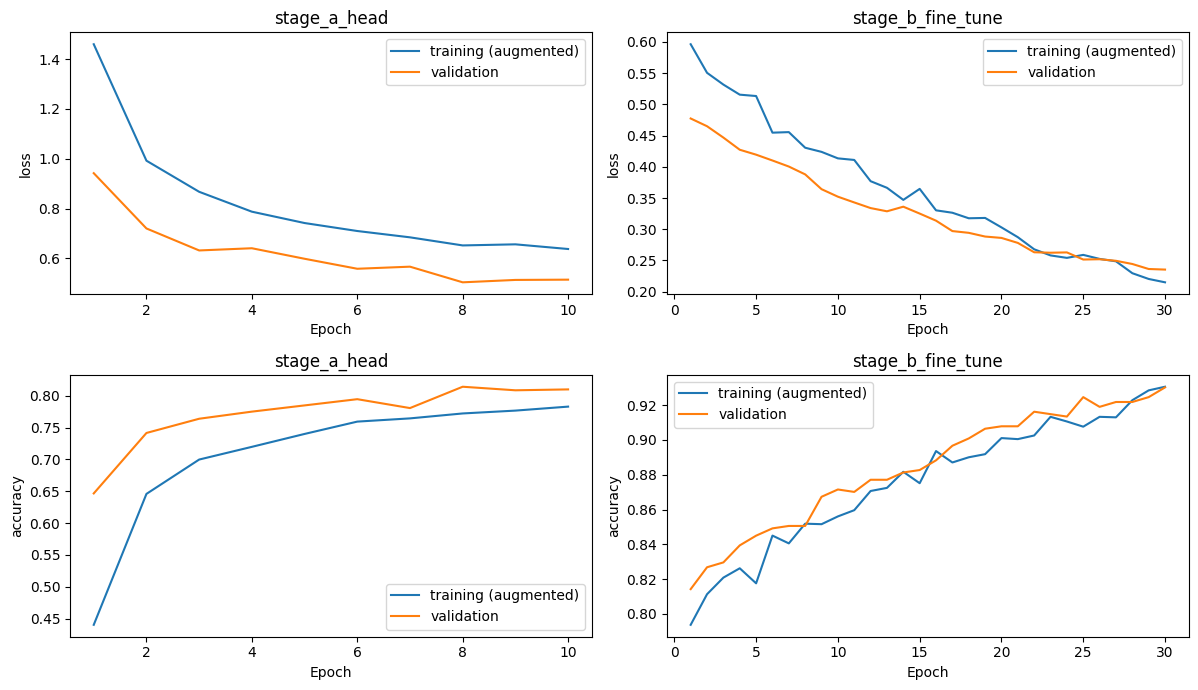

,split,images,accuracy,balanced_accuracy,macro_f1,cross_entropy
0,training without augmentation,3355,0.940089,0.941004,0.935105,0.178750
1,validation,716,0.930168,0.928527,0.924439,0.232296


In [18]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for column, stage in enumerate(("stage_a_head", "stage_b_fine_tune")):
    history = pd.read_csv(RUN_DIR / stage / "history.csv").drop_duplicates("epoch", keep="last")
    for row_index, metric in enumerate(("loss", "accuracy")):
        axes[row_index, column].plot(history.epoch + 1, history[metric], label="training (augmented)")
        axes[row_index, column].plot(history.epoch + 1, history[f"val_{metric}"], label="validation")
        axes[row_index, column].set(title=stage, xlabel="Epoch", ylabel=metric)
        axes[row_index, column].legend()
fig.tight_layout()
fig.savefig(REPORT_DIR / "learning_curves.png", dpi=150)
plt.show()
train_probabilities = predict_frame(best_model, train_frame)
deterministic_scores = pd.DataFrame([
    {"split": "training without augmentation", **metrics_for(train_frame, train_probabilities)},
    {"split": "validation", **metrics_for(validation_frame, validation_probabilities)},
])
display(deterministic_scores)
deterministic_scores.to_csv(REPORT_DIR / "deterministic_scores.csv", index=False)


## 12 · Export mobile candidates
Save a TensorFlow SavedModel and convert in an isolated CPU subprocess. The GPU training model
remains available if conversion fails. Export float32, float16 and (optionally) full-integer INT8.
INT8 calibration uses only training images, sampled across all six classes.

The inference model accepts [1,224,224,3] NHWC input. Float models take RGB float32 [0,255].
Integer models require quantization using the saved input scale and zero point, even though their
input type is uint8. Outputs follow class_names.json. These files have no Task Library metadata:
use the LiteRT Interpreter/CompiledModel APIs or add appropriate metadata before using a Task API.
[LiteRT conversion and quantization](https://ai.google.dev/edge/litert/conversion/tensorflow/quantization/post_training_quantization).


In [19]:
CONVERTER_SOURCE = '"""Executed by the notebook in a separate CPU process to isolate conversion memory."""\nimport json\nimport os\nimport sys\nfrom pathlib import Path\n\nos.environ["CUDA_VISIBLE_DEVICES"] = "-1"\nos.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"\nos.environ["KERAS_BACKEND"] = "tensorflow"\n\nimport numpy as np\nimport tensorflow as tf\n\nsaved_model, export_folder, calibration_path, requested = sys.argv[1:]\nexport_folder = Path(export_folder)\nstatus = {}\nfor variant in requested.split(","):\n    output = export_folder / f"rice_disease_{variant}.tflite"\n    try:\n        converter = tf.lite.TFLiteConverter.from_saved_model(saved_model)\n        if variant == "float16":\n            converter.optimizations = [tf.lite.Optimize.DEFAULT]\n            converter.target_spec.supported_types = [tf.float16]\n        elif variant == "int8":\n            calibration = np.load(calibration_path)\n\n            def representative_dataset():\n                for image in calibration:\n                    yield [image[None].astype(np.float32)]\n\n            converter.optimizations = [tf.lite.Optimize.DEFAULT]\n            converter.representative_dataset = representative_dataset\n            converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]\n            converter.inference_input_type = tf.uint8\n            converter.inference_output_type = tf.uint8\n        elif variant != "float32":\n            raise ValueError(f"Unknown format: {variant}")\n        model_bytes = converter.convert()\n        output.write_bytes(model_bytes)\n        status[variant] = {"status": "converted", "bytes": len(model_bytes)}\n    except Exception as error:\n        if output.exists():\n            output.unlink()\n        status[variant] = {"status": "failed", "error": str(error)}\n    (export_folder / "conversion_status.json").write_text(json.dumps(status, indent=2))\nprint(json.dumps(status, indent=2))\nif status.get("float32", {}).get("status") != "converted":\n    raise SystemExit("Float32 conversion failed. Inspect conversion.log; Keras model is preserved.")\n'


In [20]:
SAVED_MODEL_DIR = RUN_DIR / "saved_model"
best_model.export(str(SAVED_MODEL_DIR), format="tf_saved_model")
calibration_frame = pd.concat([
    group.sample(n=min(50, len(group)), random_state=SEED)
    for _, group in train_frame.groupby("label_id")
]).reset_index(drop=True)
calibration_data = np.stack([
    np.asarray(Image.open(path).convert("RGB"), dtype=np.float32)
    for path in calibration_frame.image_path
])
calibration_path = RUN_DIR / "int8_calibration.npy"
np.save(calibration_path, calibration_data)
converter_path = RUN_DIR / "convert_mobile.py"
converter_path.write_text(CONVERTER_SOURCE)
variants = ["float32", "float16"] + (["int8"] if EXPORT_INT8 else [])
conversion_env = os.environ.copy()
conversion_env["CUDA_VISIBLE_DEVICES"] = "-1"
print("Converting mobile models; detailed output is saved to conversion.log.")
with open(REPORT_DIR / "conversion.log", "w") as conversion_log:
    process = subprocess.run([
        sys.executable, str(converter_path), str(SAVED_MODEL_DIR),
        str(EXPORT_DIR), str(calibration_path), ",".join(variants),
    ], env=conversion_env, stdout=conversion_log, stderr=subprocess.STDOUT)
conversion_status_path = EXPORT_DIR / "conversion_status.json"
if conversion_status_path.exists():
    display(json.loads(conversion_status_path.read_text()))
if process.returncode != 0 or not (EXPORT_DIR / "rice_disease_float32.tflite").exists():
    raise RuntimeError(
        "Conversion did not complete. Inspect reports/conversion.log. "
        "Your best rice_disease.keras is preserved and can be downloaded immediately."
    )


INFO:tensorflow:Assets written to: /root/rice_project/runs/mobilenetv3_run_01/saved_model/assets


INFO:tensorflow:Assets written to: /root/rice_project/runs/mobilenetv3_run_01/saved_model/assets


Saved artifact at '/root/rice_project/runs/mobilenetv3_run_01/saved_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='rgb_image')
Output Type:
  TensorSpec(shape=(None, 6), dtype=tf.float32, name=None)
Captures:
  47009606871248: TensorSpec(shape=(), dtype=tf.resource, name=None)
  47009558419920: TensorSpec(shape=(), dtype=tf.resource, name=None)
  47009606872400: TensorSpec(shape=(), dtype=tf.resource, name=None)
  47013543533968: TensorSpec(shape=(), dtype=tf.resource, name=None)
  47009568673424: TensorSpec(shape=(), dtype=tf.resource, name=None)
  47013543533584: TensorSpec(shape=(), dtype=tf.resource, name=None)
  47009561946128: TensorSpec(shape=(), dtype=tf.resource, name=None)
  47009561944016: TensorSpec(shape=(), dtype=tf.resource, name=None)
  47009561945552: TensorSpec(shape=(), dtype=tf.resource, name=None)
  47009561939408: TensorSpec(shape=(), dtype=tf.resource, na

{'float32': {'status': 'converted', 'bytes': 11914396},
 'float16': {'status': 'converted', 'bytes': 5998148},
 'int8': {'status': 'converted', 'bytes': 3492248}}

In [22]:
print("Model variant:", variant)
print("All mobile scores finite:", bool(np.isfinite(probabilities).all()))

print("\nMaximum score difference:")
print(max_difference, "— required: <= 0.001")

print("\nPrediction agreement:")
print(agreement, "— required: >=", 1 - MAX_QUANTIZED_AGREEMENT_DROP)

print("\nMacro F1 drop:")
print(f1_drop, "— required: <=", MAX_QUANTIZED_F1_DROP)

print("\nLargest per-class recall drop:")
print(recall_drop, "— required: <= 0.02")

print("\nSaved Keras model:")
print(EXPORT_DIR / "rice_disease.keras")
print("File exists:", (EXPORT_DIR / "rice_disease.keras").is_file())

Model variant: float32
All mobile scores finite: True

Maximum score difference:
0.006364881992340088 — required: <= 0.001

Prediction agreement:
1.0 — required: >= 0.99

Macro F1 drop:
0.0 — required: <= 0.005

Largest per-class recall drop:
0.0 — required: <= 0.02

Saved Keras model:
/root/rice_project/runs/mobilenetv3_run_01/export/rice_disease.keras
File exists: True


## 13 · Verify exports using validation images only
Float32 conversion must closely match Keras. Compressed exports are accepted only if validation
macro F1 drops by at most 0.5 percentage points, class-label agreement is at least 99%, and no class
recall drops by more than 2 percentage points. These are engineering tolerances, not statistical
proof of equivalence. Choose the smallest passing file; still benchmark it on the target phone.
Test data does not choose the deployment format.


In [24]:
# Replace all of Cell 13 with this code.
# Uses CPU built-in kernels without XNNPACK. No retraining needed.

import shutil
import warnings
import numpy as np
import pandas as pd
import tensorflow as tf
from PIL import Image
from sklearn.metrics import f1_score, precision_recall_fscore_support

FLOAT32_SCORE_TOLERANCE = 0.01
VERIFICATION_BACKEND = "builtin_cpu_without_default_delegates"


# This replacement also fixes the interpreter used later in Cell 14.
def tflite_predict(model_path, frame, return_info=False):
    with warnings.catch_warnings():
        warnings.filterwarnings(
            "ignore",
            message=r"(?s).*tf\.lite\.Interpreter is deprecated.*",
            category=UserWarning,
        )
        interpreter = tf.lite.Interpreter(
            model_path=str(model_path),
            num_threads=2,
            experimental_op_resolver_type=(
                tf.lite.experimental.OpResolverType.BUILTIN_WITHOUT_DEFAULT_DELEGATES
            ),
        )

    interpreter.allocate_tensors()
    input_details = interpreter.get_input_details()[0]
    output_details = interpreter.get_output_details()[0]

    if list(input_details["shape"]) != [1, 224, 224, 3]:
        raise ValueError(
            f"Unexpected model input shape: {input_details['shape']}"
        )

    info = {"verification_backend": VERIFICATION_BACKEND}
    for direction, details in (
        ("input", input_details),
        ("output", output_details),
    ):
        info[direction] = {
            "shape": details["shape"].tolist(),
            "dtype": np.dtype(details["dtype"]).name,
            "scale": float(details["quantization"][0]),
            "zero_point": int(details["quantization"][1]),
        }

    predictions = []

    for path in frame.image_path:
        # Use cached, already-preprocessed 224x224 RGB images.
        with Image.open(path) as image:
            values = np.asarray(
                image.convert("RGB"), dtype=np.float32
            )[None]

        if values.shape != (1, 224, 224, 3):
            raise ValueError(f"Unexpected cached image dimensions: {path}")

        if np.issubdtype(input_details["dtype"], np.integer):
            scale, zero_point = input_details["quantization"]

            if not np.isfinite(scale) or scale <= 0:
                raise ValueError("Invalid input quantization scale.")

            bounds = np.iinfo(input_details["dtype"])
            values = np.clip(
                np.rint(values / scale + zero_point),
                bounds.min,
                bounds.max,
            )

        interpreter.set_tensor(
            input_details["index"],
            values.astype(input_details["dtype"]),
        )
        interpreter.invoke()

        scores = interpreter.get_tensor(output_details["index"])[0]

        if np.issubdtype(output_details["dtype"], np.integer):
            scale, zero_point = output_details["quantization"]

            if not np.isfinite(scale) or scale <= 0:
                raise ValueError("Invalid output quantization scale.")

            scores = (scores.astype(np.float32) - zero_point) * scale

        predictions.append(scores)

    probabilities = np.asarray(predictions, dtype=np.float32)
    expected_shape = (len(frame), len(CLASS_NAMES))

    if probabilities.shape != expected_shape:
        raise ValueError(
            f"Unexpected prediction shape: {probabilities.shape}"
        )
    if not np.isfinite(probabilities).all():
        raise ValueError("Mobile predictions contain non-finite scores.")

    return (probabilities, info) if return_info else probabilities


reference = np.asarray(validation_probabilities)

if reference.shape != (len(validation_frame), len(CLASS_NAMES)):
    raise ValueError("Reference predictions do not match the validation frame.")
if not np.isfinite(reference).all() or len(validation_frame) == 0:
    raise ValueError("Reference predictions must be nonempty and finite.")

reference_labels = reference.argmax(axis=1)
true_validation = validation_frame.label_id.to_numpy(dtype=int)
class_ids = list(range(len(CLASS_NAMES)))

reference_f1 = f1_score(
    true_validation,
    reference_labels,
    average="macro",
    zero_division=0,
)
reference_recall = precision_recall_fscore_support(
    true_validation,
    reference_labels,
    labels=class_ids,
    zero_division=0,
)[1]

mobile_rows = []
approved_exports = []
mobile_io = {}
mobile_validation_probabilities = {}

# Always verify the float32 baseline first.
verification_variants = list(dict.fromkeys(["float32", *variants]))

for variant in verification_variants:
    model_path = EXPORT_DIR / f"rice_disease_{variant}.tflite"
    print(f"Checking {variant} with XNNPACK disabled...", flush=True)

    try:
        if not model_path.is_file():
            raise FileNotFoundError(f"Model file missing: {model_path}")

        probabilities, info = tflite_predict(
            model_path,
            validation_frame,
            return_info=True,
        )

    except (RuntimeError, ValueError, OSError) as error:
        mobile_rows.append({
            "variant": variant,
            "accepted": False,
            "status": "execution_failed",
            "error": str(error),
        })
        pd.DataFrame(mobile_rows).to_csv(
            REPORT_DIR / "mobile_validation.csv",
            index=False,
        )

        # The baseline must work. Optional compressed models may be skipped.
        if variant == "float32":
            raise RuntimeError(
                "Float32 failed even without XNNPACK. "
                f"Your Keras model is preserved. Details: {error}"
            ) from error

        print(f"Skipping {variant}: {error}")
        continue

    mobile_validation_probabilities[variant] = probabilities
    mobile_io[variant] = info

    predicted = probabilities.argmax(axis=1)
    agreement = float((predicted == reference_labels).mean())
    metrics = metrics_for(validation_frame, probabilities)

    recall = precision_recall_fscore_support(
        true_validation,
        predicted,
        labels=class_ids,
        zero_division=0,
    )[1]

    f1_drop = float(reference_f1 - metrics["macro_f1"])
    recall_drop = float(np.max(reference_recall - recall))
    max_difference = float(np.max(np.abs(probabilities - reference)))

    accepted = bool(
        f1_drop <= MAX_QUANTIZED_F1_DROP
        and agreement >= 1 - MAX_QUANTIZED_AGREEMENT_DROP
        and recall_drop <= 0.02
        and (
            variant != "float32"
            or max_difference <= FLOAT32_SCORE_TOLERANCE
        )
    )

    mobile_rows.append({
        "variant": variant,
        **metrics,
        "size_mb": model_path.stat().st_size / 1e6,
        "agreement_with_keras": agreement,
        "macro_f1_drop": f1_drop,
        "largest_class_recall_drop": recall_drop,
        "max_score_difference": max_difference,
        "accepted": accepted,
        "status": "passed" if accepted else "rejected_by_validation",
        "verification_backend": VERIFICATION_BACKEND,
    })

    pd.DataFrame(mobile_rows).to_csv(
        REPORT_DIR / "mobile_validation.csv",
        index=False,
    )

    print(
        f"  Agreement={agreement:.4%}, "
        f"F1 drop={f1_drop:.6f}, "
        f"recall drop={recall_drop:.6f}, "
        f"max score difference={max_difference:.6f}"
    )

    if variant == "float32" and not accepted:
        display(pd.DataFrame(mobile_rows))
        raise RuntimeError(
            "Float32 failed validation. "
            "See the printed metrics; do not skip this check."
        )

    if accepted:
        approved_exports.append(model_path)


mobile_comparison = pd.DataFrame(mobile_rows)
display(mobile_comparison)

if not approved_exports:
    raise RuntimeError(
        "No mobile export passed validation. Your Keras model is preserved."
    )

selected_mobile = min(
    approved_exports,
    key=lambda path: path.stat().st_size,
)
selected_variant = selected_mobile.stem.removeprefix("rice_disease_")

shutil.copy2(
    selected_mobile,
    EXPORT_DIR / "rice_disease.tflite",
)

write_json(EXPORT_DIR / "mobile_io.json", {
    "selected_variant": selected_variant,
    "selected_io": mobile_io[selected_variant],
    "all_converted_variants": mobile_io,
    "verification_backend": VERIFICATION_BACKEND,
    "deployment_note": (
        "Revalidate on the target phone/runtime "
        "before enabling acceleration delegates."
    ),
    "quantization": (
        "q = round(real / scale + zero_point); clip to dtype range. "
        "Dequantize output as (q - zero_point) * scale."
    ),
})

write_json(REPORT_DIR / "locked_selection.json", {
    "keras_model_sha256": sha256_file(
        EXPORT_DIR / "rice_disease.keras"
    ),
    "mobile_model_sha256": sha256_file(
        EXPORT_DIR / "rice_disease.tflite"
    ),
    "selected_stage": winning_stage,
    "selected_mobile_variant": selected_variant,
    "selection_data": "validation only",
    "verification_backend": VERIFICATION_BACKEND,
    "float32_score_tolerance": FLOAT32_SCORE_TOLERANCE,
})

print("Locked deployment format:", selected_variant)
print("Continue to Cell 14, then Cell 15. No retraining is required.")

Checking float32 with XNNPACK disabled...
  Agreement=100.0000%, F1 drop=0.000000, recall drop=0.000000, max score difference=0.006363
Checking float16 with XNNPACK disabled...
  Agreement=100.0000%, F1 drop=0.000000, recall drop=0.000000, max score difference=0.045603
Checking int8 with XNNPACK disabled...
  Agreement=51.1173%, F1 drop=0.536862, recall drop=0.941176, max score difference=0.999982


,variant,images,accuracy,balanced_accuracy,macro_f1,cross_entropy,size_mb,agreement_with_keras,macro_f1_drop,largest_class_recall_drop,max_score_difference,accepted,status,verification_backend
0,float32,716,0.930168,0.928527,0.924439,0.232292,11.914396,1.000000,0.000000,0.000000,0.006363,True,passed,builtin_cpu_without_default_delegates
1,float16,716,0.930168,0.928527,0.924439,0.231507,5.998148,1.000000,0.000000,0.000000,0.045603,True,passed,builtin_cpu_without_default_delegates
2,int8,716,0.519553,0.434896,0.387576,5.112633,3.492248,0.511173,0.536862,0.941176,0.999982,False,rejected_by_validation,builtin_cpu_without_default_delegates


Locked deployment format: float16
Continue to Cell 14, then Cell 15. No retraining is required.


## 14 · Final evaluation on the held-out test set
Run after model and export selection are locked. Report accuracy, balanced accuracy, macro F1,
per-class precision/recall, confusion matrix, and errors for both Keras and the selected mobile file.
Do not use these test results to keep adjusting settings. If you do, obtain a fresh final test set.

This internal test is not a substitute for a separately collected, expert-labelled field test.
The model cannot establish that an unfamiliar image is a supported rice disease merely from a
high softmax score. No treatment recommendation or reliable unknown-image detector is trained here.


,model,images,accuracy,balanced_accuracy,macro_f1,cross_entropy
0,keras,734,0.893733,0.88594,0.883198,0.366386
1,mobile,734,0.893733,0.88594,0.883198,0.365237


,precision,recall,f1-score,support
Bacterial Leaf Blight,0.813559,0.914286,0.860987,105.000000
Brown Spot,0.953586,0.918699,0.935818,246.000000
Healthy Rice Leaf,0.942308,0.989899,0.965517,99.000000
Leaf Blast,0.784314,0.833333,0.808081,96.000000
Leaf scald,0.888889,0.833333,0.860215,96.000000
Sheath Blight,0.915663,0.826087,0.868571,92.000000
accuracy,0.893733,0.893733,0.893733,0.893733
macro avg,0.883053,0.885940,0.883198,734.000000
weighted avg,0.896680,0.893733,0.894095,734.000000


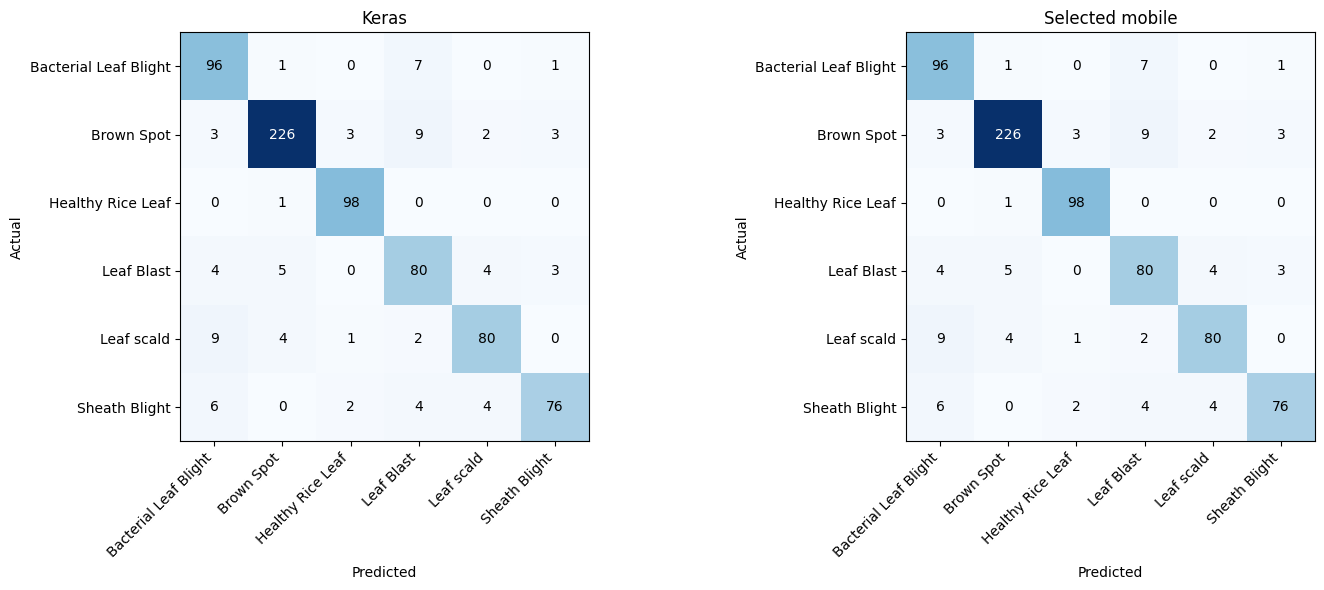

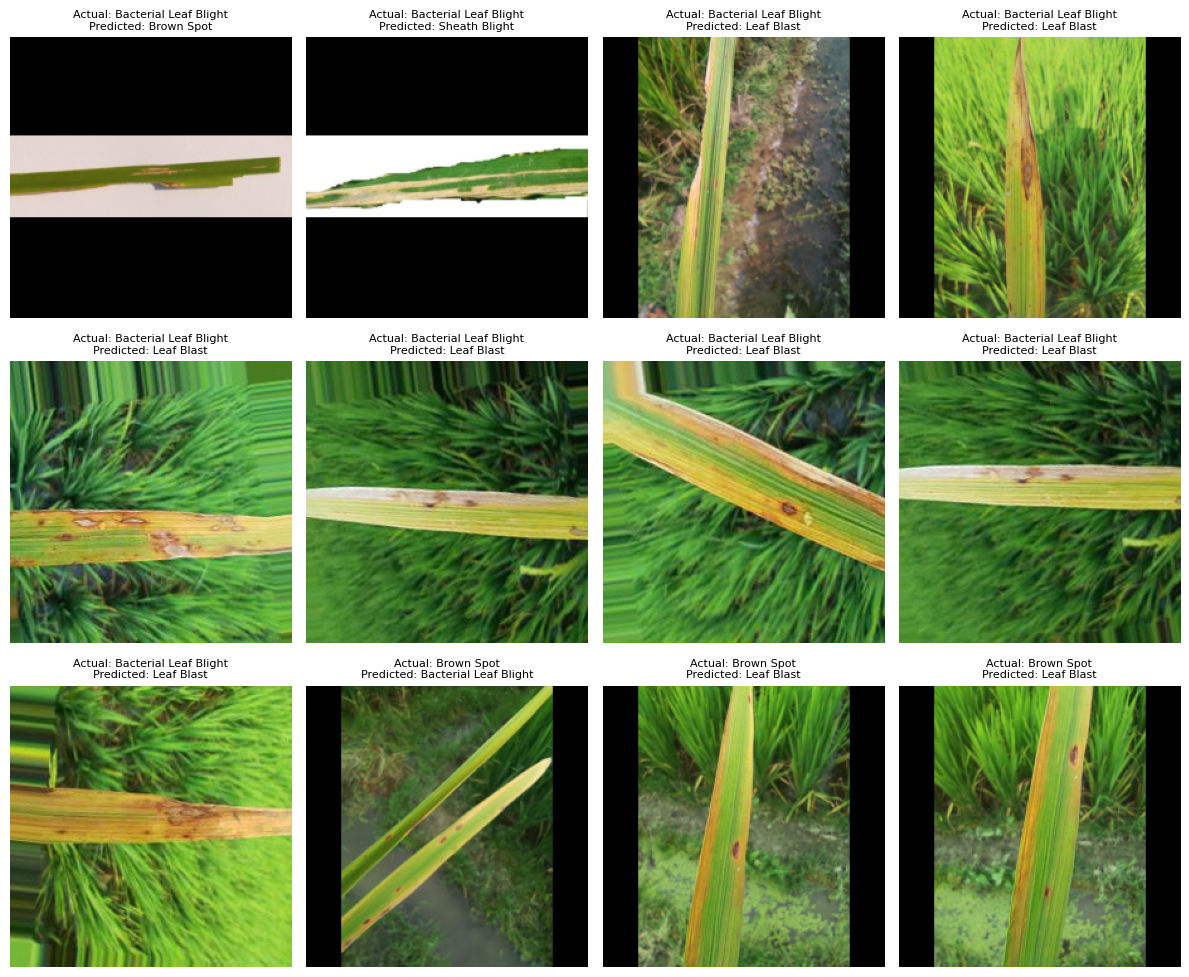

In [25]:
test_probabilities = predict_frame(best_model, test_frame)
test_mobile_probabilities = tflite_predict(EXPORT_DIR / "rice_disease.tflite", test_frame)
test_results = {
    "keras": metrics_for(test_frame, test_probabilities),
    "mobile": metrics_for(test_frame, test_mobile_probabilities),
    "mobile_variant": selected_variant,
    "agreement": float((test_probabilities.argmax(axis=1) ==
                        test_mobile_probabilities.argmax(axis=1)).mean()),
}
write_json(REPORT_DIR / "test_metrics.json", test_results)
display(pd.DataFrame([{"model": name, **test_results[name]} for name in ("keras", "mobile")]))
for name, probabilities in [("keras", test_probabilities), ("mobile", test_mobile_probabilities)]:
    save_predictions(test_frame, probabilities, REPORT_DIR / f"test_{name}_predictions.csv")
    report = classification_report(
        test_frame.label_id, probabilities.argmax(axis=1), labels=list(range(6)),
        target_names=CLASS_NAMES, output_dict=True, zero_division=0,
    )
    pd.DataFrame(report).transpose().to_csv(REPORT_DIR / f"classification_report_{name}.csv")
display(pd.DataFrame(classification_report(
    test_frame.label_id, test_probabilities.argmax(axis=1), labels=list(range(6)),
    target_names=CLASS_NAMES, output_dict=True, zero_division=0,
)).transpose())
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for axis, name, probabilities in zip(
    axes, ("Keras", "Selected mobile"), (test_probabilities, test_mobile_probabilities)
):
    matrix = confusion_matrix(test_frame.label_id, probabilities.argmax(axis=1), labels=list(range(6)))
    axis.imshow(matrix, cmap="Blues")
    for (row, column), value in np.ndenumerate(matrix):
        axis.text(column, row, str(value), ha="center", va="center",
                  color="white" if value > matrix.max() / 2 else "black")
    axis.set(xticks=range(6), yticks=range(6), xticklabels=CLASS_NAMES,
             yticklabels=CLASS_NAMES, xlabel="Predicted", ylabel="Actual", title=name)
    plt.setp(axis.get_xticklabels(), rotation=45, ha="right")
fig.tight_layout()
fig.savefig(REPORT_DIR / "confusion_matrices.png", dpi=150)
plt.show()
errors = np.flatnonzero(test_probabilities.argmax(axis=1) != test_frame.label_id.to_numpy())
if len(errors):
    fig, axes = plt.subplots(3, 4, figsize=(12, 10))
    for axis in axes.flat:
        axis.axis("off")
    for axis, index in zip(axes.flat, errors[:12]):
        row = test_frame.iloc[index]
        axis.imshow(Image.open(row.image_path))
        axis.set_title(
            f"Actual: {row.label}\nPredicted: {CLASS_NAMES[test_probabilities[index].argmax()]}",
            fontsize=8,
        )
    fig.tight_layout()
    fig.savefig(REPORT_DIR / "test_errors.png", dpi=140)
    plt.show()
else:
    print("No test errors. Independently verify labels and leakage before claiming perfect performance.")


## 15 · Package and download
The ZIP contains the Keras model, selected mobile model, passing alternative mobile models,
ordered labels, input specifications, reference prediction script and reports. It excludes your
source photographs and large resumable-training backups. Dataset sample/error report images are
included; omit those PNGs before sharing the package if your image licence does not permit sharing.

Download rice_leaf_model_bundle.zip from the Modal Files panel, using the path printed below.
Keep the project Volume if you want to resume/retrain. Stop the kernel when finished.


In [26]:
PREDICT_SOURCE = '"""Reference Keras prediction. Usage: python predict.py /path/to/photo.jpg"""\nimport json\nimport os\nimport sys\nfrom pathlib import Path\n\nos.environ["KERAS_BACKEND"] = "tensorflow"\nimport numpy as np\nimport tensorflow as tf\nfrom PIL import Image, ImageOps\n\n\ndef prepare_image(path):\n    with Image.open(path) as source:\n        image = ImageOps.exif_transpose(source)\n        if image.mode in ("RGBA", "LA") or "transparency" in image.info:\n            rgba = image.convert("RGBA")\n            image = Image.alpha_composite(\n                Image.new("RGBA", rgba.size, (0, 0, 0, 255)), rgba)\n        image = image.convert("RGB")\n        image = ImageOps.contain(image, (224, 224), Image.Resampling.BILINEAR)\n        canvas = Image.new("RGB", (224, 224), (0, 0, 0))\n        canvas.paste(image, ((224 - image.width) // 2, (224 - image.height) // 2))\n        return np.asarray(canvas, dtype=np.float32)[None]\n\n\ndef predict(path, model_directory=None):\n    folder = Path(model_directory or Path(__file__).parent)\n    labels = json.loads((folder / "class_names.json").read_text())\n    model = tf.keras.models.load_model(folder / "rice_disease.keras", compile=False)\n    scores = model.predict(prepare_image(path), verbose=0)[0]\n    order = np.argsort(scores)[::-1]\n    return {\n        "predicted_class": labels[int(order[0])],\n        "model_score": float(scores[order[0]]),\n        "top_three": [{"class": labels[int(i)], "model_score": float(scores[i])}\n                      for i in order[:3]],\n        "note": "Uncalibrated closed-set scores; not a confirmed diagnosis or unknown-image detector.",\n    }\n\n\nif __name__ == "__main__":\n    print(json.dumps(predict(sys.argv[1]), indent=2))\n'


In [27]:
write_json(EXPORT_DIR / "preprocessing.json", {
    "input_shape": [1, 224, 224, 3], "layout": "NHWC",
    "orientation": "Apply EXIF transpose before resizing.",
    "color": "RGB; composite transparency on black; do not use BGR.",
    "resize": "Preserve aspect ratio using Pillow ImageOps.contain with bilinear interpolation.",
    "padding": "Center on black 224x224 canvas; floor division for top/left offsets.",
    "float_input_range": [0, 255],
    "normalization": "Inside MobileNetV3. Do not divide by 255 or apply a second normalization.",
    "output": "Six softmax scores in class_names.json order, not calibrated diagnostic probabilities.",
    "integer_input": "Read mobile_io.json and apply the selected model's scale/zero_point.",
    "pillow_version": importlib.metadata.version("Pillow"),
    "mobile_parity": "Platform resize implementations can differ. Validate preprocessing with reference cases.",
})
(EXPORT_DIR / "predict.py").write_text(PREDICT_SOURCE)
shutil.copy2(RUN_DIR / "experiment_config.json", EXPORT_DIR / "experiment_config.json")
shutil.copy2(REPORT_DIR / "environment.txt", EXPORT_DIR / "training_environment.txt")
(EXPORT_DIR / "inference_requirements.txt").write_text(
    "tensorflow==2.20.0\nkeras==3.11.3\nnumpy==2.2.6\nPillow==11.3.0\n")

# Small decoded synthetic cases make mobile preprocessing parity testable without sharing farm photos.
reference_cases = EXPORT_DIR / "reference_cases"
reference_cases.mkdir(exist_ok=True)
rng = np.random.default_rng(SEED)
synthetic = Image.fromarray(rng.integers(0, 256, (173, 311, 3), dtype=np.uint8))
synthetic.save(reference_cases / "input.png")
prepared = np.asarray(letterbox(synthetic), dtype=np.float32)
np.save(reference_cases / "expected_rgb224.npy", prepared)
scores = best_model.predict(prepared[None], verbose=0)[0]
write_json(reference_cases / "expected_keras_scores.json", [float(v) for v in scores])

unknown_group_fraction = float(1 - grouped.capture_group_known.mean())
model_card = f"""# Rice leaf disease classifier

Backbone: ImageNet-pretrained MobileNetV3Large, alpha 1.0, 224x224.
Winning stage: {winning_stage}.
Selected mobile variant: {selected_variant}.
Cleaned images: {len(manifest)}.
Train / validation / test: {len(train_frame)} / {len(validation_frame)} / {len(test_frame)}.
Exact class order: {json.dumps(CLASS_NAMES)}.
Images without known capture-group metadata: {unknown_group_fraction:.1%}.

## Evaluation
Keras test accuracy: {test_results['keras']['accuracy']:.4f}.
Keras test macro F1: {test_results['keras']['macro_f1']:.4f}.
Mobile test accuracy: {test_results['mobile']['accuracy']:.4f}.
Mobile test macro F1: {test_results['mobile']['macro_f1']:.4f}.
These are internal held-out results, not independent field performance estimates.
Model, epoch, and mobile format selection used validation data only.

## Intended use and limits
Research prototype for one principal supported rice leaf/sheath condition per photo.
Six-class scores are uncalibrated. High confidence does not establish a diagnosis.
Healthy means no visible symptoms among supported labels, not absence of all disease.
Unknown diseases, mixed infections, non-rice inputs and poor images can be misclassified.
Near-duplicate grouping cannot discover every same-plant, same-farm or transformed image.
Expert label review, independent smartphone field testing and device benchmarking remain necessary.
No pesticide recommendation, clinical-style probability, severity estimate or validated rejection
mechanism is provided. Link disease labels to a separately reviewed local agricultural guide.

## Files
rice_disease.keras: full float32 Keras inference model; use compile=False to load.
rice_disease.tflite: selected mobile export; see mobile_io.json for tensor types.
class_names.json / labels.txt: exact output order.
preprocessing.json / predict.py: image preprocessing and Python prediction reference.
reference_cases: synthetic preprocessing parity case (not an accuracy test).
reports: audit records, split manifest, learning curves, metrics and prediction tables.
training_environment.txt: full environment snapshot, not a minimal deployment dependency list.

## Provenance
Archive SHA256: {archive_sha256}.
Class labels are derived from user-provided folders and have not been independently confirmed.
Record dataset source/licence and agricultural reviewer in your project documentation.
"""
(EXPORT_DIR / "MODEL_CARD.md").write_text(model_card)

bundle_path = RUN_DIR / "rice_leaf_model_bundle.zip"
allowed_models = {p.name for p in approved_exports} | {"rice_disease.tflite"}
bundle_files = []
with zipfile.ZipFile(bundle_path, "w", compression=zipfile.ZIP_DEFLATED, compresslevel=6) as bundle:
    for path in sorted(EXPORT_DIR.rglob("*")):
        if not path.is_file():
            continue
        if path.suffix == ".tflite" and path.name not in allowed_models:
            continue
        relative = path.relative_to(EXPORT_DIR).as_posix()
        bundle.write(path, relative)
        bundle_files.append({"path": relative, "sha256": sha256_file(path)})
    for path in sorted(REPORT_DIR.rglob("*")):
        if path.is_file():
            relative = "reports/" + path.relative_to(REPORT_DIR).as_posix()
            bundle.write(path, relative)
            bundle_files.append({"path": relative, "sha256": sha256_file(path)})
    bundle.writestr("file_checksums.json", json.dumps(bundle_files, indent=2))
with zipfile.ZipFile(bundle_path) as bundle:
    if bundle.testzip() is not None:
        raise RuntimeError("ZIP integrity check failed.")
if hasattr(os, "sync"):
    os.sync()
print("DOWNLOAD FROM THE MODAL FILES PANEL:")
print(bundle_path)
print(f"Bundle size: {bundle_path.stat().st_size / 1e6:.1f} MB")
print("Keras model:", EXPORT_DIR / "rice_disease.keras")
print("Mobile model:", EXPORT_DIR / "rice_disease.tflite")
print("SHA256:", sha256_file(bundle_path))


2026-10-12 08:12:33.719709: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


DOWNLOAD FROM THE MODAL FILES PANEL:
/root/rice_project/runs/mobilenetv3_run_01/rice_leaf_model_bundle.zip
Bundle size: 40.1 MB
Keras model: /root/rice_project/runs/mobilenetv3_run_01/export/rice_disease.keras
Mobile model: /root/rice_project/runs/mobilenetv3_run_01/export/rice_disease.tflite
SHA256: a6d63d9ccd3e1de48ba5f54096171431ce8c494decbff98cf97b396ca18685cb


## 16 · Optional: try a new farmer photograph
Upload a photograph to your Volume and set PHOTO_PATH. This uses the same EXIF/RGB/resize steps
as training. The top scores are model scores, not proof that the plant has the predicted disease.
Keep a separate, labelled field set for measuring real-world performance.


In [28]:
PHOTO_PATH = None  # Example: VOLUME_ROOT / "new_leaf.jpg"
if PHOTO_PATH is not None:
    rgb = open_rgb(PHOTO_PATH)
    image = np.asarray(letterbox(rgb), dtype=np.float32)[None]
    probabilities = best_model.predict(image, verbose=0)[0]
    display(pd.DataFrame({
        "class": CLASS_NAMES, "model_score": probabilities,
    }).sort_values("model_score", ascending=False).head(3))
    plt.imshow(rgb)
    plt.axis("off")
    plt.show()
else:
    print("Optional: set PHOTO_PATH to test one new image.")


Optional: set PHOTO_PATH to test one new image.


## Troubleshooting
| Symptom | Action |
|---|---|
| Upload path not found | Read the actual path in the Files panel and update ZIP_PATH. |
| No classes found | Use the six folder names from the sample below; a parent folder is allowed. |
| Identical image has two labels | Resolve reports/label_conflicts.csv; create a corrected ZIP. |
| No GPU detected | Select L4, install the dependencies in the new kernel, then restart. |
| Out of GPU memory | Use batch size 16 and a new RUN_NAME. |
| Session stops | Restart, reinstall if needed, rerun setup and data cells with the same RUN_NAME. |
| Settings changed error | Use a new RUN_NAME. Prior checkpoints stay preserved. |
| Conversion fails | Download the Keras model; inspect reports/conversion.log before changing versions. |
| INT8 fails or degrades | The verified float16/float32 export remains available. |
| High dataset score, poor farmer photos | Collect independent field images, review labels/background bias. |

Recognized folder names:
Bacterial Leaf Blight; Brown Spot; Healthy Rice Leaf; Leaf Blast; Leaf scald; Sheath Blight.
Use one class per folder and ordinary image files inside. Underscores and case differences are accepted.
The ZIP is a dataset archive, not a set of six nested ZIP archives.


In [29]:
from pathlib import Path
from datetime import datetime, timezone
import shutil
import zipfile

# Your trained models from the completed notebook.
source = Path(EXPORT_DIR)

required_files = [
    "rice_disease.keras",
    "rice_disease.tflite",
    "class_names.json",
    "preprocessing.json",
    "mobile_io.json",
]

missing = [name for name in required_files if not (source / name).is_file()]
if missing:
    raise FileNotFoundError(f"Missing files: {missing}. Complete Cell 15 first.")

# Create a new export folder without overwriting previous exports.
stamp = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S_%f")
final_folder = Path("/root") / f"Rice_Leaf_Final_Model_{stamp}"
final_folder.mkdir(exist_ok=False)

optional_files = [
    "labels.txt",
    "predict.py",
    "inference_requirements.txt",
    "MODEL_CARD.md",
    "experiment_config.json",
    "training_environment.txt",
]

for name in required_files + optional_files:
    file = source / name
    if file.is_file():
        shutil.copy2(file, final_folder / name)

# Include evaluation results and charts.
if Path(REPORT_DIR).is_dir():
    shutil.copytree(Path(REPORT_DIR), final_folder / "reports")

# Create a ZIP containing the new folder.
zip_path = Path(shutil.make_archive(
    str(final_folder),
    "zip",
    root_dir=final_folder.parent,
    base_dir=final_folder.name,
))

with zipfile.ZipFile(zip_path) as archive:
    damaged = archive.testzip()
    if damaged:
        raise RuntimeError(f"ZIP verification failed: {damaged}")

print("✅ Final model package created")
print("Folder:", final_folder)
print("DOWNLOAD THIS FILE:", zip_path)
print(f"ZIP size: {zip_path.stat().st_size / (1024 ** 2):.2f} MB")

✅ Final model package created
Folder: /root/Rice_Leaf_Final_Model_20261012_081734_431993
DOWNLOAD THIS FILE: /root/Rice_Leaf_Final_Model_20261012_081734_431993.zip
ZIP size: 22.11 MB
